##**TASK 1**

In [1]:
# Step 1: Import libraries
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Step 2: Load MNIST dataset
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# Step 3: Reshape images
train_images = train_images.reshape(60000, 28, 28, 1)
test_images = test_images.reshape(10000, 28, 28, 1)

# Step 4: Normalize images
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

# Step 5: Convert labels into categorical format
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# Step 6: Build CNN model
model = models.Sequential()

# First convolution group
model.add(layers.Conv2D(32, (5, 5),
                        activation='relu',
                        input_shape=(28, 28, 1)))

model.add(layers.MaxPooling2D((2, 2)))

# Second convolution group
model.add(layers.Conv2D(64, (5, 5),
                        activation='relu'))

model.add(layers.MaxPooling2D((2, 2)))

# Flatten layer
model.add(layers.Flatten())

# Output layer
model.add(layers.Dense(10, activation='softmax'))

# Step 7: Display model summary
model.summary()

# Step 8: Compile model
model.compile(
    optimizer='sgd',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Step 9: Train model
history = model.fit(
    train_images,
    train_labels,
    batch_size=100,
    epochs=10,
    verbose=1,
    validation_split=0.1
)

# Step 10: Evaluate model
test_loss, test_acc = model.evaluate(
    test_images,
    test_labels
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

# Step 11: Make a prediction
import numpy as np

prediction = model.predict(test_images[:1])
predicted_digit = np.argmax(prediction)

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", np.argmax(test_labels[0]))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,346 (243.54 KB)

 Trainable params: 62,346 (243.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 56s 103ms/step - accuracy: 0.7426 - loss: 0.9867 - val_accuracy: 0.9265 - val_loss: 0.2695
Epoch 2/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 55s 101ms/step - accuracy: 0.9175 - loss: 0.2823 - val_accuracy: 0.9438 - val_loss: 0.1963
Epoch 3/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 82s 101ms/step - accuracy: 0.9403 - loss: 0.2047 - val_accuracy: 0.9617 - val_loss: 0.1353
Epoch 4/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 54s 99ms/step - accuracy: 0.9530 - loss: 0.1618 - val_accuracy: 0.9692 - val_loss: 0.1132
Epoch 5/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 55s 101ms/step - accuracy: 0.9603 - loss: 0.1359 - val_accuracy: 0.9732 - val_loss: 0.0987
Epoch 6/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 81s 99ms/step - accuracy: 0.9649 - loss: 0.1195 - val_accuracy: 0.9762 - val_loss: 0.0871
Epoch 7/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 54s 99ms/step - accuracy: 0.9684 - loss: 0.1066 - val_accuracy: 0.9750 - val_loss: 0.0867
Epoch 8/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.9711 - loss: 0.096

##**TASK 2**

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Training Model 1: Basic CNN
Epoch 1/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 47s 86ms/step - accuracy: 0.5262 - loss: 1.4096 - val_accuracy: 0.6560 - val_loss: 0.8380
Epoch 2/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 81s 84ms/step - accuracy: 0.7174 - loss: 0.7503 - val_accuracy: 0.7582 - val_loss: 0.6594
Epoch 3/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 47s 87ms/step - accuracy: 0.7526 - loss: 0.6564 - val_accuracy: 0.7708 - val_loss: 0.6090
Epoch 4/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 82s 87ms/step - accuracy: 0.7754 - loss: 0.5969 - val_accuracy: 0.7862 - val_loss: 0.5688
Epoch 5/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 46s 84ms/step - accuracy: 0.7903 - loss: 0.5588 - val_accuracy: 0.7990 - val_loss: 0.5485
Model 1 Test Accuracy: 0.7924000024795532

Training Model 2: RMSprop
Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 140s 164ms/step - accuracy: 0

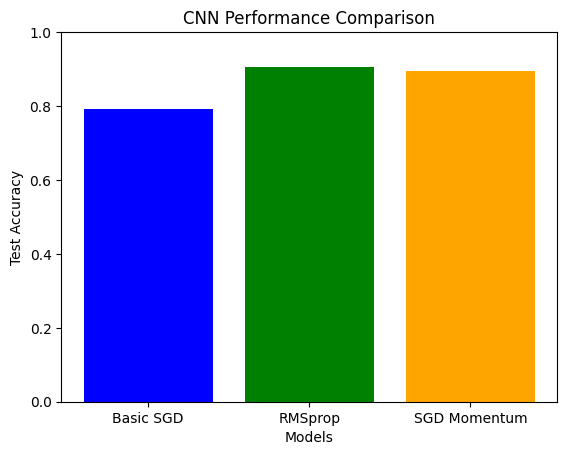

In [2]:

# ==========================================
# LAB TASK 2: ENHANCING CNN PERFORMANCE
# Dataset: Fashion MNIST
# ==========================================

# Step 1: Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import models, layers
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD

# Step 2: Load Fashion MNIST dataset
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

# Step 3: Reshape images
train_images = train_images.reshape(60000, 28, 28, 1)
test_images = test_images.reshape(10000, 28, 28, 1)

# Step 4: Normalize images
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

# Step 5: One-hot encode labels
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)


# ==========================================
# FUNCTION TO BUILD CNN MODEL
# ==========================================

def build_cnn(filters1, filters2, optimizer):

    model = models.Sequential()

    # First convolution layer
    model.add(layers.Conv2D(
        filters1, (3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ))

    model.add(layers.MaxPooling2D((2, 2)))

    # Second convolution layer
    model.add(layers.Conv2D(
        filters2, (3, 3),
        activation='relu'
    ))

    model.add(layers.MaxPooling2D((2, 2)))

    # Third convolution layer
    model.add(layers.Conv2D(
        filters2, (3, 3),
        activation='relu'
    ))

    # Flatten
    model.add(layers.Flatten())

    # Dense layer
    model.add(layers.Dense(128, activation='relu'))

    # Output layer
    model.add(layers.Dense(10, activation='softmax'))

    # Compile model
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# ==========================================
# MODEL 1: BASIC CNN WITH SGD
# ==========================================

print("\nTraining Model 1: Basic CNN")

model1 = build_cnn(
    filters1=32,
    filters2=64,
    optimizer='sgd'
)

history1 = model1.fit(
    train_images,
    train_labels,
    batch_size=100,
    epochs=5,
    validation_split=0.1,
    verbose=1
)

loss1, acc1 = model1.evaluate(
    test_images, test_labels, verbose=0
)

print("Model 1 Test Accuracy:", acc1)


# ==========================================
# MODEL 2: IMPROVED CNN WITH RMSPROP
# ==========================================

print("\nTraining Model 2: RMSprop")

model2 = build_cnn(
    filters1=64,
    filters2=128,
    optimizer='rmsprop'
)

history2 = model2.fit(
    train_images,
    train_labels,
    batch_size=64,
    epochs=10,
    validation_split=0.1,
    verbose=1
)

loss2, acc2 = model2.evaluate(
    test_images, test_labels, verbose=0
)

print("Model 2 Test Accuracy:", acc2)


# ==========================================
# MODEL 3: SGD WITH MOMENTUM
# ==========================================

print("\nTraining Model 3: SGD with Momentum")

momentum_optimizer = SGD(
    learning_rate=0.01,
    momentum=0.9
)

model3 = build_cnn(
    filters1=64,
    filters2=128,
    optimizer=momentum_optimizer
)

history3 = model3.fit(
    train_images,
    train_labels,
    batch_size=64,
    epochs=10,
    validation_split=0.1,
    verbose=1
)

loss3, acc3 = model3.evaluate(
    test_images, test_labels, verbose=0
)

print("Model 3 Test Accuracy:", acc3)


# ==========================================
# COMPARE ALL MODELS
# ==========================================

print("\n========== MODEL COMPARISON ==========")

print("Basic CNN Accuracy:", acc1)
print("RMSprop Accuracy:", acc2)
print("SGD Momentum Accuracy:", acc3)

# Find best model
accuracies = [acc1, acc2, acc3]
best_model = np.argmax(accuracies) + 1

print("Best Model: Model", best_model)
print("Best Accuracy:", max(accuracies))


# ==========================================
# PLOT MODEL COMPARISON
# ==========================================

model_names = ['Basic SGD', 'RMSprop', 'SGD Momentum']

plt.bar(model_names, accuracies, color=['blue', 'green', 'orange'])

plt.title("CNN Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

plt.show()
